# prompt-shot — Image Generation with FLUX
### Apple Silicon Mac M4 · 16 GB Unified Memory · **MLX Backend**

**Model:** [black-forest-labs/FLUX.1-schnell](https://huggingface.co/black-forest-labs/FLUX.1-schnell) / [FLUX.1-dev](https://huggingface.co/black-forest-labs/FLUX.1-dev)  
**Runtime:** [MLX](https://github.com/ml-explore/mlx) + [mflux](https://github.com/filipstrand/mflux) — Apple's native ML framework  
**Why MLX over PyTorch MPS:** zero-copy unified memory · lazy graph compilation · all ops native on Metal · ~1.5–2.5× faster inference

---
**Setup (run once in terminal):**
```bash
uv sync --group mlx
uv run --group mlx python -m ipykernel install --user --name prompt-shot --display-name "Python (prompt-shot)"
# Then select the "Python (prompt-shot)" kernel in VS Code before running cells
```

## 1 · Import Libraries

In [ ]:
import os, platform, subprocess, time, pathlib, warnings
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ── MLX / mflux ────────────────────────────────────────────────────────────
try:
    import mlx.core as mx
    from mflux.models.flux.variants.txt2img.flux import Flux1
    from mflux.models.common.config.model_config import ModelConfig
    import mflux as _mflux
except ImportError as e:
    raise ImportError(
        f"MLX/mflux not installed: {e}\n"
        "Run:  uv sync\n"
        "Then relaunch jupyter with: uv run jupyter notebook prompt-shot-mlx.ipynb"
    ) from e

print("Libraries loaded.")
print(f"  mlx    : {mx.__version__}")
print(f"  mflux  : (installed)")
print(f"  numpy  : {np.__version__}")
print(f"  MLX default device : {mx.default_device()}")

Libraries loaded.
  mlx    : 0.31.1
  mflux  : (installed)
  numpy  : 2.4.3
  MLX default device : Device(gpu, 0)


## 2 · Load HuggingFace Token from .env
Create a `.env` file in this folder with:
```
HF_API_KEY=hf_YOUR_TOKEN_HERE
```
Accept the model license at https://huggingface.co/black-forest-labs/FLUX.1-schnell  
Generate a token at https://huggingface.co/settings/tokens

In [ ]:
from dotenv import load_dotenv
load_dotenv()
hf_api_key = os.getenv("hf_api_key")

from huggingface_hub import login, whoami
login(token=hf_api_key, add_to_git_credential=False)

info = whoami()
print(f"✓ Logged in as: {info['name']}")

✓ Logged in as: Abhishek-ta


## 3 · Validate Hardware & Configure Threads
MLX uses Apple Silicon unified memory natively — no separate GPU allocation needed.

In [ ]:
arch      = platform.machine()
ram_gb    = int(subprocess.check_output(["sysctl","-n","hw.memsize"])) / 1024**3
cpu_count = os.cpu_count()

assert arch == "arm64", f"MLX requires Apple Silicon (arm64), got {arch}"
assert ram_gb >= 16,    f"Expected ≥16 GB RAM, found {ram_gb:.1f} GB"

# M4: 4 performance cores + 6 efficiency cores
P_CORES = 4
os.environ.update({
    "OMP_NUM_THREADS":        str(P_CORES),
    "MKL_NUM_THREADS":        str(P_CORES),
    "VECLIB_MAXIMUM_THREADS": str(P_CORES),
    "TOKENIZERS_PARALLELISM": "false",
    "NPY_MMAP_THRESHOLD":     str(512 * 1024 * 1024),   # 512 MB
})

print(f"✓ Apple Silicon arm64  |  RAM: {ram_gb:.0f} GB  |  Cores: {cpu_count}")
print(f"  MLX device : {mx.default_device()}")
print(f"  CPU thread limit (P-cores): {P_CORES}")

✓ Apple Silicon arm64  |  RAM: 16 GB  |  Cores: 10
  MLX device : Device(gpu, 0)
  CPU thread limit (P-cores): 4


## 4 · MLX Benchmark
Confirms Metal GPU acceleration before loading the model.

In [ ]:
N, REPS = 2048, 5

# ── MLX (Metal GPU via lazy graph) ────────────────────────────────────────
a, b = mx.random.normal((N, N)), mx.random.normal((N, N))
_ = a @ b; mx.eval(_)                    # warm-up
t0 = time.perf_counter()
for _ in range(REPS): c = a @ b
mx.eval(c)
t_mlx = (time.perf_counter() - t0) / REPS

# ── NumPy (CPU / vecLib BLAS) ──────────────────────────────────────────────
an = np.random.randn(N, N).astype(np.float32)
_ = an @ an
t0 = time.perf_counter()
for _ in range(REPS): cn = an @ an
t_np = (time.perf_counter() - t0) / REPS

print(f"Matrix multiply {N}×{N}, avg of {REPS} runs:")
print(f"  NumPy (CPU / vecLib)  : {t_np*1000:7.1f} ms")
print(f"  MLX   (Metal GPU)     : {t_mlx*1000:7.1f} ms  ({t_np/t_mlx:.1f}× speedup)")
if t_mlx < t_np:
    print("✓ Metal GPU acceleration confirmed.")

Matrix multiply 2048×2048, avg of 5 runs:
  NumPy (CPU / vecLib)  :    12.5 ms
  MLX   (Metal GPU)     :     1.8 ms  (7.1× speedup)
✓ Metal GPU acceleration confirmed.


## 5 · Load FLUX Model with mflux

| Setting | Value | Notes |
|---|---|---|
| `MODEL_NAME` | `"schnell"` | 4-step, fast, open license. Use `"dev"` for higher quality (20 steps) |
| `QUANTIZE` | `4` | 4-bit ≈ 4 GB RAM — **best for 16 GB**. Use `8` for better quality at ~8 GB |

> First run downloads weights (~4–8 GB depending on quantization) and caches them in `~/.cache/huggingface/hub/`.

In [ ]:
import time
import os
from mflux.models.flux2.variants.txt2img.flux2_klein import Flux2Klein
from mflux.models.common.config.model_config import ModelConfig

# ── Configuration ──────────────────────────────────────────────────────────
# Use ModelConfig.flux2_klein_4b()      for the distilled (4-step) version.
# Use ModelConfig.flux2_klein_base_4b() for the non-distilled (20+ step) version.
# 9B variants are also available: flux2_klein_9b() / flux2_klein_base_9b()
MODEL_NAME = "flux2-klein-4b"
QUANTIZE   = 4  # 4-bit is the sweet spot for 16GB M4 RAM

print(f"🚀 Loading {MODEL_NAME} (Quantization: {QUANTIZE}-bit)...")
t0 = time.perf_counter()

try:
    flux = Flux2Klein(
        model_config=ModelConfig.flux2_klein_4b(),
        quantize=QUANTIZE,
        # Optional: uncomment if you hit Memory Pressure errors
        # lora_paths=None,
    )
    t1 = time.perf_counter()
    print(f"✅ Model loaded and ready in {t1 - t0:.2f} seconds.")

except Exception as e:
    print(f"❌ Error: {e}")
    print("Ensure you've accepted the model terms at: https://huggingface.co/black-forest-labs/FLUX.2-klein-4B")


🚀 Loading flux2-klein-4b (Quantization: 4-bit)...
✅ Model loaded and ready in 0.75 seconds.


In [ ]:
import os
from huggingface_hub import constants

print(f"Your HF cache is located at: {constants.HF_HUB_CACHE}")

Your HF cache is located at: /Users/abhisheksaxena/.cache/huggingface/hub


## 6 · Generate Image from Prompt
Edit `PROMPT` and parameters, then run. Images are saved to `outputs/`.

Generating 1024×1024 image (4 steps) …


100%|██████████| 4/4 [02:57<00:00, 44.48s/it]


Done in 183.4 s  →  outputs/flux2_klein_1775236659.png


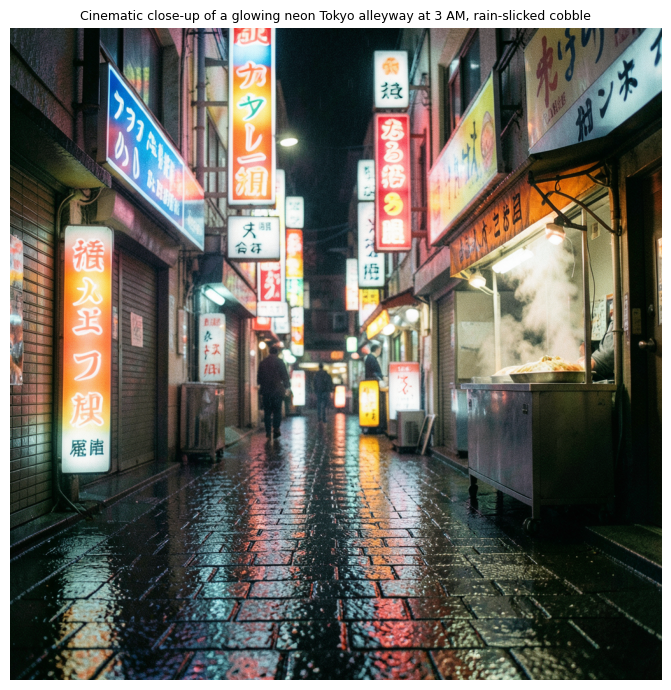

In [ ]:
OUTPUT_DIR = pathlib.Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# ── Edit these ─────────────────────────────────────────────────────────────
PROMPT   = "Cinematic close-up of a glowing neon Tokyo alleyway at 3 AM, rain-slicked cobblestones reflecting \
     multicolored signs in Japanese, steam rising from a ramen stall, shallow depth of field, 35mm film grain, 4K"
HEIGHT   = 1024    # multiples of 16
WIDTH    = 1024
STEPS    = 4       # flux2-klein-4b (distilled): 4 | flux2-klein-base-4b: 20+
GUIDANCE = 1.0     # flux2-klein default; try 1.5–3.5 for stronger prompt adherence
SEED     = 42      # set to None for random

print(f"Generating {WIDTH}×{HEIGHT} image ({STEPS} steps) …")
t0 = time.perf_counter()

result = flux.generate_image(
    seed=SEED if SEED is not None else int(time.time()),
    prompt=PROMPT,
    num_inference_steps=STEPS, #set to 4 for distilled flux2-klein-4b, 20+ for non-distilled flux2-klein-base-4b
    height=HEIGHT,
    width=WIDTH,
    guidance=GUIDANCE, #flux2-klein default; try 1.5–3.5 for stronger prompt adherence
)

elapsed = time.perf_counter() - t0
image: Image.Image = result.image

out_path = OUTPUT_DIR / f"flux2_klein_{int(time.time())}.png"
image.save(out_path)
print(f"Done in {elapsed:.1f} s  →  {out_path}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(image); ax.axis("off")
ax.set_title(PROMPT[:80], fontsize=9, wrap=True)
plt.tight_layout(); plt.show()


Generating 1024×1024 image (4 steps) …


100%|██████████| 4/4 [02:08<00:00, 32.01s/it]


Done in 132.1 s  →  outputs/flux2_klein_1775237036.png


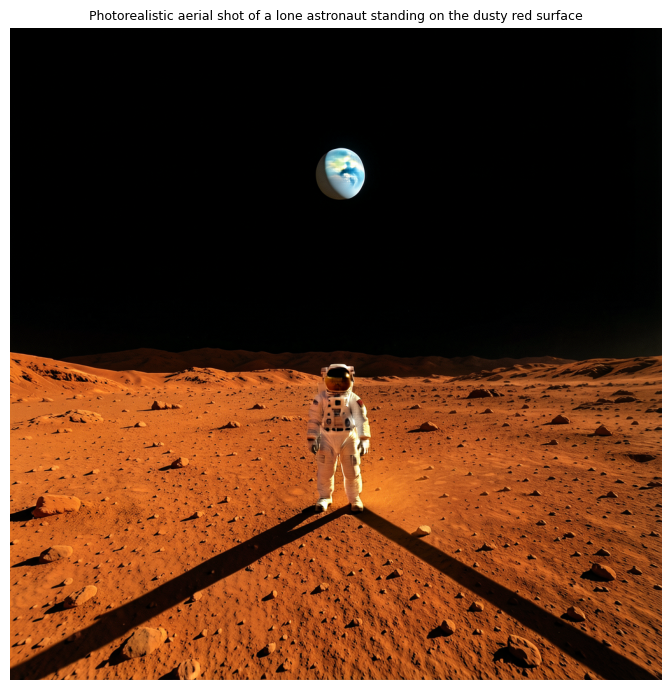

In [ ]:
OUTPUT_DIR = pathlib.Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# ── Edit these ─────────────────────────────────────────────────────────────
PROMPT   = "Photorealistic aerial shot of a lone astronaut standing on the dusty red surface of Mars, \
      Earth visible as a pale blue dot in the black sky, long shadow, golden hour light, ISO noise, 4K DSLR"
HEIGHT   = 1024    # multiples of 16
WIDTH    = 1024
STEPS    = 4       # flux2-klein-4b (distilled): 4 | flux2-klein-base-4b: 20+
GUIDANCE = 3.5    # flux2-klein default; try 1.5–3.5 for stronger prompt adherence
SEED     = 42      # set to None for random

print(f"Generating {WIDTH}×{HEIGHT} image ({STEPS} steps) …")
t0 = time.perf_counter()

result = flux.generate_image(
    seed=SEED if SEED is not None else int(time.time()),
    prompt=PROMPT,
    num_inference_steps=STEPS,
    height=HEIGHT,
    width=WIDTH,
    guidance=GUIDANCE,
)

elapsed = time.perf_counter() - t0
image: Image.Image = result.image

out_path = OUTPUT_DIR / f"flux2_klein_{int(time.time())}.png"
image.save(out_path)
print(f"Done in {elapsed:.1f} s  →  {out_path}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(image); ax.axis("off")
ax.set_title(PROMPT[:80], fontsize=9, wrap=True)
plt.tight_layout(); plt.show()


## 6b · Shorts / Vertical Image (9:16)
Generate a portrait-orientation image optimised for YouTube Shorts, Instagram Reels, or TikTok.

| Setting | Value | Notes |
|---|---|---|
| Resolution | `576 × 1024` | Exact 9:16 ratio, multiples of 16, fits in 16 GB RAM |
| `STEPS` | `4` | Distilled model — 4 steps is the sweet spot |
| `GUIDANCE` | `3.5` | Higher than default for stronger prompt adherence on complex scenes |

Generating 576×1024 (9:16 Shorts) image …


100%|██████████| 4/4 [00:50<00:00, 12.70s/it]


Done in 54.2 s  →  outputs/flux2_klein_shorts_1775237377.png


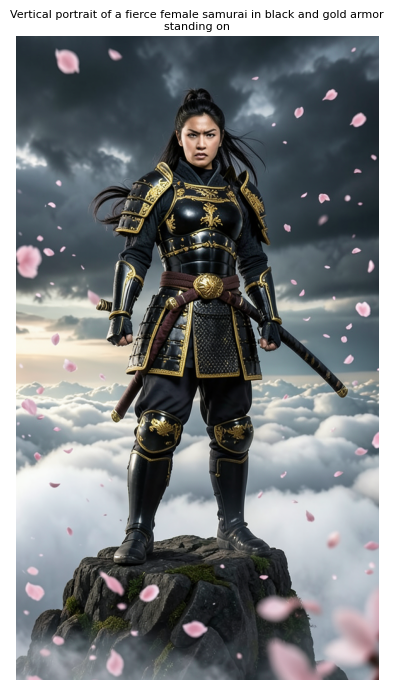

In [ ]:
# ── 9:16 Shorts configuration ─────────────────────────────────────────────
SHORTS_PROMPT   = "Vertical portrait of a fierce female samurai in black and gold armor standing on a mountain peak \
      above the clouds, cherry blossoms swirling in the wind, dramatic stormy sky, cinematic lighting"
SHORTS_HEIGHT   = 1024   # 9:16 → 576 × 1024
SHORTS_WIDTH    = 576
SHORTS_STEPS    = 4      # distilled flux2-klein-4b
SHORTS_GUIDANCE = 1.0    # stronger adherence than default 1.0; good for detailed scenes
SHORTS_SEED     = 42

print(f"Generating {SHORTS_WIDTH}×{SHORTS_HEIGHT} (9:16 Shorts) image …")
t0 = time.perf_counter()

result_shorts = flux.generate_image(
    seed=SHORTS_SEED,
    prompt=SHORTS_PROMPT,
    num_inference_steps=SHORTS_STEPS,
    height=SHORTS_HEIGHT,
    width=SHORTS_WIDTH,
    guidance=SHORTS_GUIDANCE,
)

elapsed = time.perf_counter() - t0
shorts_image: Image.Image = result_shorts.image

shorts_path = OUTPUT_DIR / f"flux2_klein_shorts_{int(time.time())}.png"
shorts_image.save(shorts_path)
print(f"Done in {elapsed:.1f} s  →  {shorts_path}")

# Display at native aspect ratio
fig, ax = plt.subplots(figsize=(4, 7))
ax.imshow(shorts_image); ax.axis("off")
ax.set_title(SHORTS_PROMPT[:80], fontsize=8, wrap=True)
plt.tight_layout(); plt.show()


Generating 576×1024 (9:16 Shorts) image …


100%|██████████| 4/4 [01:22<00:00, 20.74s/it]


Done in 85.5 s  →  outputs/flux2_klein_shorts_1775237480.png


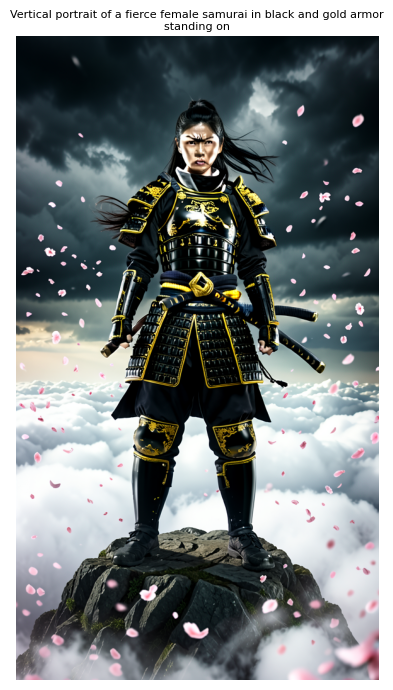

In [ ]:
# ── 9:16 Shorts configuration ─────────────────────────────────────────────
SHORTS_PROMPT   = "Vertical portrait of a fierce female samurai in black and gold armor standing on a \
      mountain peak above the clouds, cherry blossoms swirling in the wind, dramatic stormy sky, cinematic lighting"
SHORTS_HEIGHT   = 1024   # 9:16 → 576 × 1024
SHORTS_WIDTH    = 576
SHORTS_STEPS    = 4      # distilled flux2-klein-4b
SHORTS_GUIDANCE = 3.5   # stronger adherence than default 1.0; good for detailed scenes
SHORTS_SEED     = 42

print(f"Generating {SHORTS_WIDTH}×{SHORTS_HEIGHT} (9:16 Shorts) image …")
t0 = time.perf_counter()

result_shorts = flux.generate_image(
    seed=SHORTS_SEED,
    prompt=SHORTS_PROMPT,
    num_inference_steps=SHORTS_STEPS,
    height=SHORTS_HEIGHT,
    width=SHORTS_WIDTH,
    guidance=SHORTS_GUIDANCE,
)

elapsed = time.perf_counter() - t0
shorts_image: Image.Image = result_shorts.image

shorts_path = OUTPUT_DIR / f"flux2_klein_shorts_{int(time.time())}.png"
shorts_image.save(shorts_path)
print(f"Done in {elapsed:.1f} s  →  {shorts_path}")

# Display at native aspect ratio
fig, ax = plt.subplots(figsize=(4, 7))
ax.imshow(shorts_image); ax.axis("off")
ax.set_title(SHORTS_PROMPT[:80], fontsize=8, wrap=True)
plt.tight_layout(); plt.show()


## 7 · Batch Generation
Generate multiple images from a list of prompts and display as a grid.

[1/3] A futuristic city at night with neon lights, cyberpunk, high …


100%|██████████| 4/4 [02:57<00:00, 44.38s/it]


  saved → outputs/flux_batch_00_1775237695.png
[2/3] Underwater coral reef teeming with colorful fish, cinematic  …


100%|██████████| 4/4 [03:37<00:00, 54.26s/it]


  saved → outputs/flux_batch_01_1775237917.png
[3/3] Portrait of an astronaut on Mars, golden hour, photorealisti …


100%|██████████| 4/4 [03:13<00:00, 48.39s/it]


  saved → outputs/flux_batch_02_1775238115.png


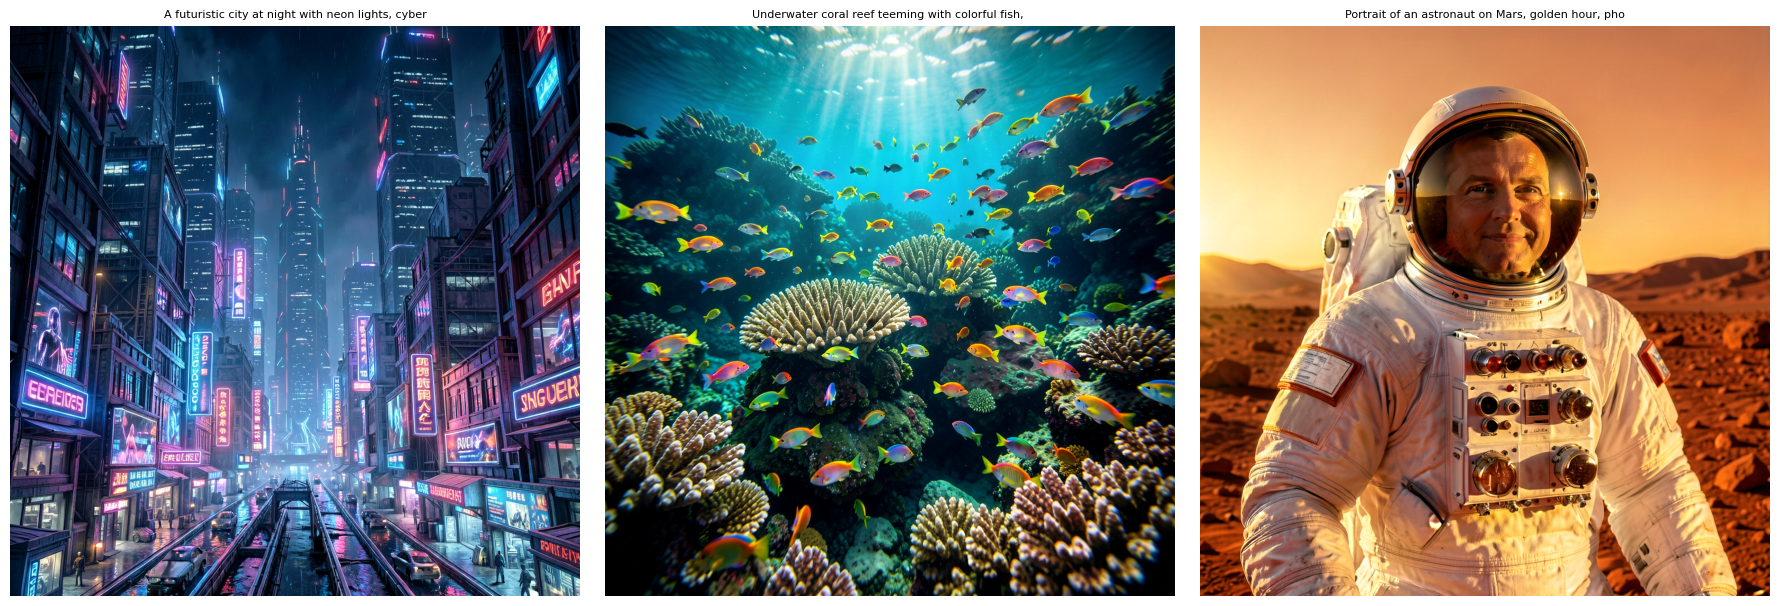

In [ ]:
PROMPTS = [
    "A futuristic city at night with neon lights, cyberpunk, highly detailed",
    "Underwater coral reef teeming with colorful fish, cinematic lighting",
    "Portrait of an astronaut on Mars, golden hour, photorealistic",
]

saved_paths = []
for i, prompt in enumerate(PROMPTS):
    print(f"[{i+1}/{len(PROMPTS)}] {prompt[:60]} …")
    res = flux.generate_image(
        seed=i,
        prompt=prompt,
        num_inference_steps=STEPS,
        height=HEIGHT,
        width=WIDTH,
        guidance=GUIDANCE,
    )
    p = OUTPUT_DIR / f"flux_batch_{i:02d}_{int(time.time())}.png"
    res.image.save(p); saved_paths.append(p)
    print(f"  saved → {p}")

fig, axes = plt.subplots(1, len(saved_paths), figsize=(6 * len(saved_paths), 6))
if len(saved_paths) == 1: axes = [axes]
for ax, p, pr in zip(axes, saved_paths, PROMPTS):
    ax.imshow(Image.open(p)); ax.axis("off")
    ax.set_title(pr[:50], fontsize=8, wrap=True)
plt.tight_layout(); plt.show()

## 8 · Watermark Image Generation
Generate a compact 160×160 px image (smallest multiple of 16 that covers 150×150), then crop to exactly 150×150 px.  
Designed for use as a logo watermark overlay on generated content.  
Edit `WATERMARK_PROMPT` to match your brand/channel aesthetic.

Generating 160×160 px image, will crop to 150×150 …


100%|██████████| 4/4 [04:42<00:00, 70.52s/it]


Done in 283.8 s  →  outputs/watermark.png  (final size: (150, 150))


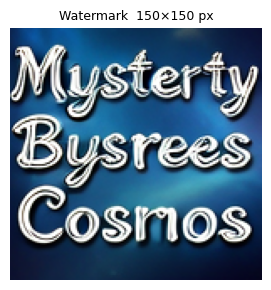

In [ ]:
OUTPUT_DIR = pathlib.Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# ── Watermark configuration ────────────────────────────────────────────────
# FLUX requires dimensions that are multiples of 16.
# 160×160 is the smallest valid size ≥ 150×150; we crop to 150×150 after generation.
WATERMARK_PROMPT = (
    "Create a text style image suitable for watermark overlay. Text should read MysteryBytesCosmos"
)
WM_GEN_SIZE = 160   # multiple of 16 — FLUX minimum constraint
WM_FINAL    = 150   # target watermark size after centre-crop
WM_STEPS    = 4
WM_GUIDANCE = 3.5   # high adherence — important for logo-style fidelity
WM_SEED     = 7

print(f"Generating {WM_GEN_SIZE}×{WM_GEN_SIZE} px image, will crop to {WM_FINAL}×{WM_FINAL} …")
t0 = time.perf_counter()

wm_result = flux.generate_image(
    seed=WM_SEED,
    prompt=WATERMARK_PROMPT,
    num_inference_steps=WM_STEPS,
    height=WM_GEN_SIZE,
    width=WM_GEN_SIZE,
    guidance=WM_GUIDANCE,
)

elapsed = time.perf_counter() - t0
wm_image: Image.Image = wm_result.image

# Centre-crop to exactly 150×150
left = (WM_GEN_SIZE - WM_FINAL) // 2
wm_image = wm_image.crop((left, left, left + WM_FINAL, left + WM_FINAL))
assert wm_image.size == (WM_FINAL, WM_FINAL), f"Unexpected size: {wm_image.size}"

wm_path = OUTPUT_DIR / "watermark.png"
wm_image.save(wm_path)
print(f"Done in {elapsed:.1f} s  →  {wm_path}  (final size: {wm_image.size})")

fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(wm_image); ax.axis("off")
ax.set_title(f"Watermark  {WM_FINAL}×{WM_FINAL} px", fontsize=9)
plt.tight_layout(); plt.show()
